In [96]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [97]:
df = pd.read_csv("quora_duplicate_questions.csv")
df.shape

(404290, 6)

In [98]:
df = df.sample(30000, random_state=2)

In [99]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30000 entries, 398782 to 312470
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            30000 non-null  int64 
 1   qid1          30000 non-null  int64 
 2   qid2          30000 non-null  int64 
 3   question1     30000 non-null  object
 4   question2     30000 non-null  object
 5   is_duplicate  30000 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 1.6+ MB


In [100]:
df.isnull().sum()

id              0
qid1            0
qid2            0
question1       0
question2       0
is_duplicate    0
dtype: int64

In [101]:
df.duplicated().sum()

np.int64(0)

In [102]:
df = df.dropna()

is_duplicate
0    19013
1    10987
Name: count, dtype: int64
is_duplicate
0    63.376667
1    36.623333
Name: count, dtype: float64


<Axes: xlabel='is_duplicate'>

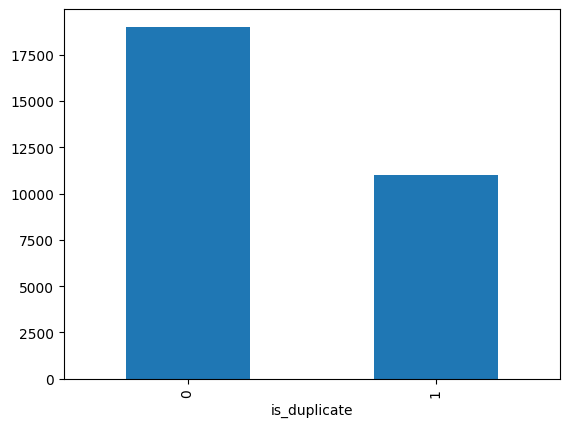

In [103]:
# Distribution of duplicate and non-duplicate questions 
print(df['is_duplicate'].value_counts())
print(df['is_duplicate'].value_counts()/df['is_duplicate'].count()*100)
df['is_duplicate'].value_counts().plot(kind='bar')

In [104]:
# repeated questions

qid = pd.Series(df['qid1'].tolist()+df['qid2'].tolist())
print('number of unique questions', np.unique(qid).shape[0])
x = qid.value_counts()>1
print('number of questions getting repeated', x[x].shape[0])

number of unique questions 55299
number of questions getting repeated 3480


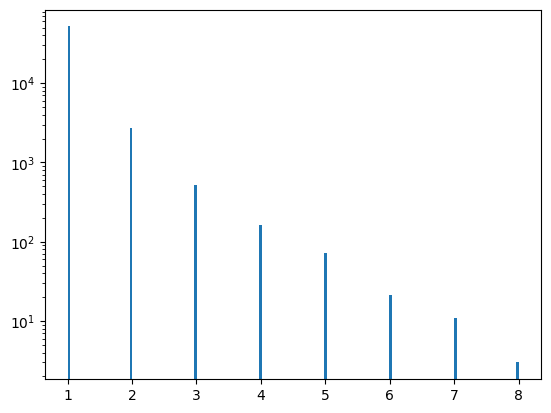

In [105]:
# Repeated questions histogram
plt.hist(qid.value_counts().values, bins=160)
plt.yscale('log')
plt.show()

In [106]:
## feature Engineering
df['q1_len']= df['question1'].str.len()
df['q2_len']= df['question2'].str.len()


In [107]:
df.head(2)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1,76,77
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0,49,57


In [108]:
df['q1_num_words'] = df['question1'].apply(lambda row: len(row.split(" ")))
df['q2_num_words'] = df['question2'].apply(lambda row: len(row.split(" ")))
df.head(3)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1,76,77,12,12
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0,49,57,12,15
327711,327711,454161,454162,I am from India and live abroad. I met a guy f...,T.I.E.T to Thapar University to Thapar Univers...,0,105,120,25,17


In [109]:
## common words 
def common_wordds(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))
    return len(w1 & w2)

In [110]:
df['word_common'] = df.apply(common_wordds, axis=1)
df.head(2)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1,76,77,12,12,11
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0,49,57,12,15,7


In [111]:
def total_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))
    return (len(w1)+len(w2))

In [112]:
df['word_total'] = df.apply(total_words,axis=1)
df.head(2)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1,76,77,12,12,11,24
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0,49,57,12,15,7,23


In [113]:
df['word_share'] = round(df['word_common']/df['word_total'],2)
df.head(2)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1,76,77,12,12,11,24,0.46
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0,49,57,12,15,7,23,0.30


minimum characters 2
maximum characters 391
Average num of characters 59


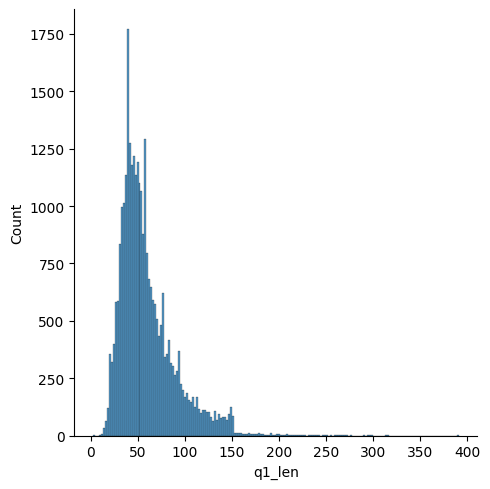

In [114]:
## analysis of features 
sns.displot(df['q1_len'])
print('minimum characters', df['q1_len'].min())
print('maximum characters', df['q1_len'].max())
print('Average num of characters', int(df['q1_len'].mean()))

minimum characters 6
maximum characters 1151
Average num of characters 60


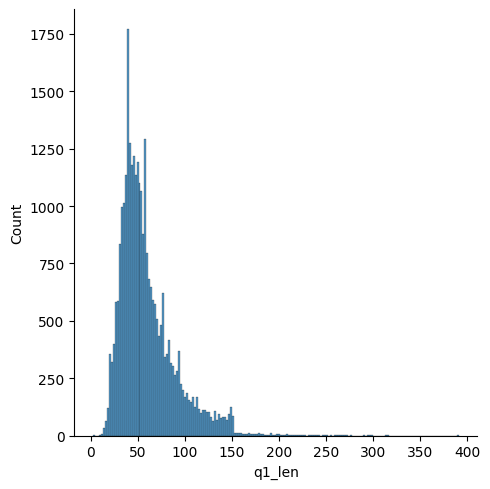

In [115]:
sns.displot(df['q1_len'])
print('minimum characters', df['q2_len'].min())
print('maximum characters', df['q2_len'].max())
print('Average num of characters', int(df['q2_len'].mean()))

minimum characters 1
maximum characters 72
Average num of characters 10


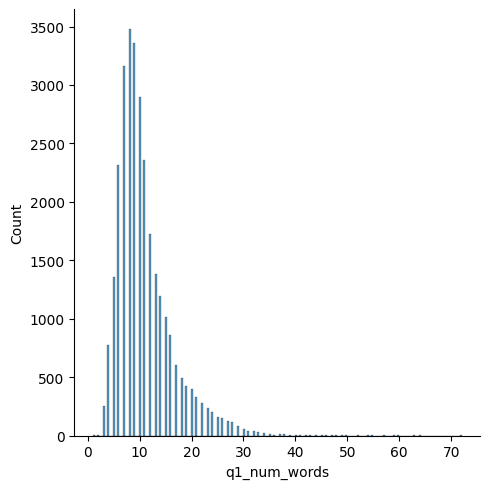

In [116]:
sns.displot(df['q1_num_words'])
print('minimum characters', df['q1_num_words'].min())
print('maximum characters', df['q1_num_words'].max())
print('Average num of characters', int(df['q1_num_words'].mean()))

minimum characters 1
maximum characters 237
Average num of characters 11


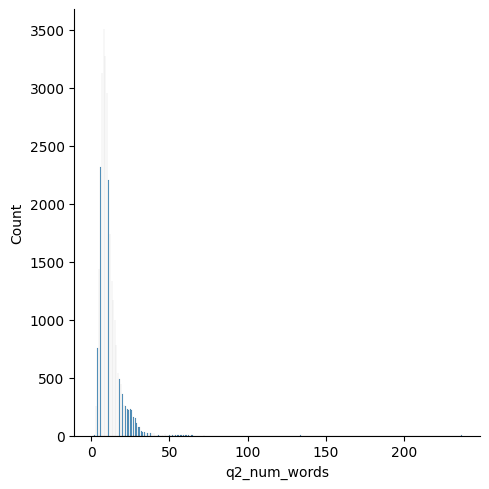

In [117]:
sns.displot(df['q2_num_words'])
print('minimum characters', df['q2_num_words'].min())
print('maximum characters', df['q2_num_words'].max())
print('Average num of characters', int(df['q2_num_words'].mean()))

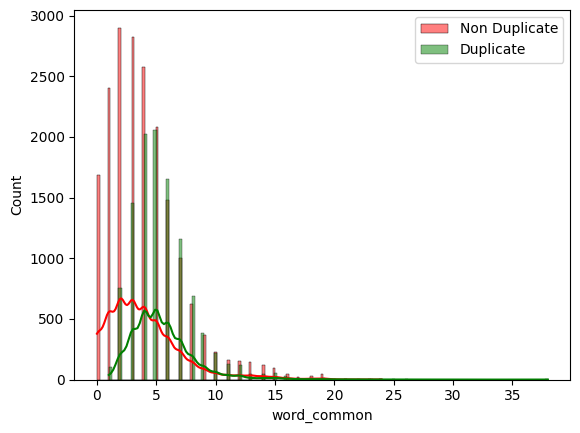

In [118]:
sns.histplot(df[df['is_duplicate']==0]['word_common'], label='Non Duplicate', color='red', kde=True)
sns.histplot(df[df['is_duplicate']==1]['word_common'], label='Duplicate', color='green', kde=True)

plt.legend()
plt.show()


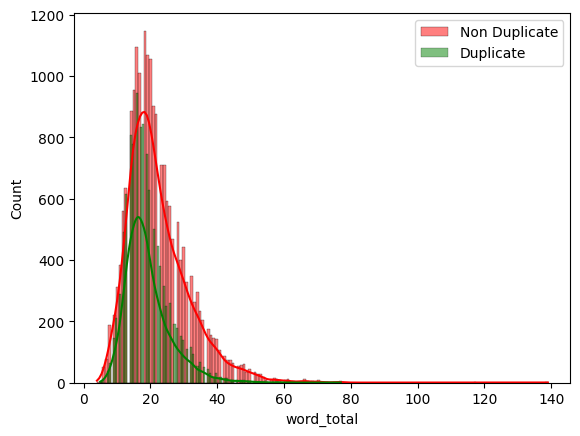

In [119]:
sns.histplot(df[df['is_duplicate']==0]['word_total'], label='Non Duplicate', color='red', kde=True)
sns.histplot(df[df['is_duplicate']==1]['word_total'], label='Duplicate', color='green', kde=True)

plt.legend()
plt.show()

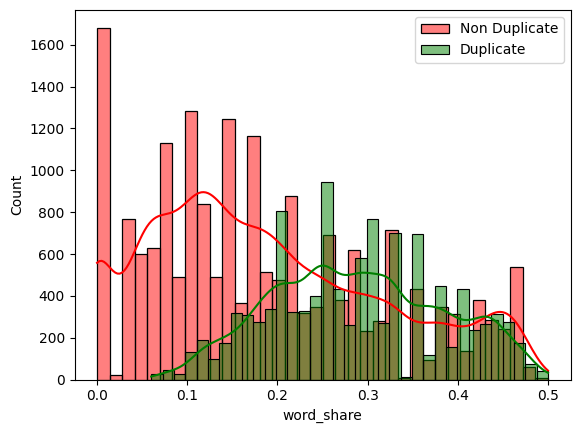

In [120]:
sns.histplot(df[df['is_duplicate']==0]['word_share'], label='Non Duplicate', color='red', kde=True)
sns.histplot(df[df['is_duplicate']==1]['word_share'], label='Duplicate', color='green', kde=True)

plt.legend()
plt.show()

In [121]:
## dataset 
ques_df = df[['question1', 'question2']]
ques_df.head()

,question1,question2
398782,What is the best marketing automation tool for...,What is the best marketing automation tool for...
115086,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...
327711,I am from India and live abroad. I met a guy f...,T.I.E.T to Thapar University to Thapar Univers...
367788,Why do so many people in the U.S. hate the sou...,My boyfriend doesnt feel guilty when he hurts ...
151235,Consequences of Bhopal gas tragedy?,What was the reason behind the Bhopal gas trag...


In [122]:
final_df = df.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df.shape)
final_df.head(5)

(30000, 8)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
398782,1,76,77,12,12,11,24,0.46
115086,0,49,57,12,15,7,23,0.30
327711,0,105,120,25,17,2,34,0.06
367788,0,59,146,12,30,0,32,0.00
151235,0,35,50,5,9,3,13,0.23


In [123]:
from sklearn.feature_extraction.text import CountVectorizer 
questions = list(ques_df['question1'])+ list(ques_df['question2'])

cv = CountVectorizer(max_features=3000)
q1_arr , q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)

In [124]:
temp_df1 = pd.DataFrame(q1_arr, index=ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index=ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2],axis=1)
temp_df.shape

(30000, 6000)

In [125]:
final_df = pd.concat([final_df, temp_df], axis=1)
print(final_df.shape)
final_df.head()

(30000, 6008)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,0,1,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
398782,1,76,77,12,12,11,24,0.46,0,0,...,0,0,0,0,0,0,0,0,0,0
115086,0,49,57,12,15,7,23,0.30,0,0,...,0,0,0,0,0,0,0,0,0,0
327711,0,105,120,25,17,2,34,0.06,0,0,...,0,0,0,0,0,0,0,0,0,0
367788,0,59,146,12,30,0,32,0.00,0,0,...,0,0,0,1,0,0,0,0,0,0
151235,0,35,50,5,9,3,13,0.23,0,0,...,0,0,0,0,0,0,0,0,0,0


In [126]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(final_df.iloc[:,1:].values,final_df.iloc[:,0].values,test_size=0.2,random_state=42) 

In [127]:
from sklearn.ensemble import RandomForestClassifier 
from sklearn.metrics import accuracy_score 
rf = RandomForestClassifier()
rf.fit(x_train,y_train)
y_pred = rf.predict(x_test)
accuracy_score(y_test, y_pred)

0.7715

In [129]:
pip install xgboost


     ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
     ---------------------------------------- 0.1/101.7 MB 2.8 MB/s eta 0:00:36
     ---------------------------------------- 0.3/101.7 MB 3.2 MB/s eta 0:00:33
     ---------------------------------------- 0.3/101.7 MB 2.6 MB/s eta 0:00:39
     ---------------------------------------- 0.3/101.7 MB 2.6 MB/s eta 0:00:39
     ---------------------------------------- 0.3/101.7 MB 2.6 MB/s eta 0:00:39
     ---------------------------------------- 0.3/101.7 MB 2.6 MB/s eta 0:00:39
     ---------------------------------------- 0.3/101.7 MB 2.6 MB/s eta 0:00:39
     ---------------------------------------- 0.3/101.7 MB 2.6 MB/s eta 0:00:39
     ---------------------------------------- 0.3/101.7 MB 2.6 MB/s eta 0:00:39
     ---------------------------------------- 0.3/101.7 MB 2.6 MB/s eta 0:00:39
     ---------------------------------------- 0.3/101.7 MB 2.6 MB/s eta 0:00:39
     ---------------------------------------- 


[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


     ------------ -------------------------- 31.8/101.7 MB 2.0 MB/s eta 0:00:35
     ------------ -------------------------- 31.9/101.7 MB 2.0 MB/s eta 0:00:35
     ------------ -------------------------- 32.1/101.7 MB 2.0 MB/s eta 0:00:35
     ------------ -------------------------- 32.1/101.7 MB 2.0 MB/s eta 0:00:36
     ------------ -------------------------- 32.2/101.7 MB 2.0 MB/s eta 0:00:36
     ------------ -------------------------- 32.3/101.7 MB 2.0 MB/s eta 0:00:36
     ------------ -------------------------- 32.5/101.7 MB 2.0 MB/s eta 0:00:35
     ------------ -------------------------- 32.7/101.7 MB 2.1 MB/s eta 0:00:34
     ------------ -------------------------- 32.9/101.7 MB 2.2 MB/s eta 0:00:32
     ------------ -------------------------- 33.1/101.7 MB 2.2 MB/s eta 0:00:32
     ------------ -------------------------- 33.3/101.7 MB 2.2 MB/s eta 0:00:32
     ------------ -------------------------- 33.4/101.7 MB 2.2 MB/s eta 0:00:32
     ------------ ----------------------

In [130]:
from xgboost import XGBClassifier 
xgb = XGBClassifier()
xgb.fit(x_train,y_train)
y_pred = xgb.predict(x_test)
accuracy_score(y_test, y_pred)

0.7668333333333334